<a href="https://colab.research.google.com/github/halynazhabchyk/nlp_labs/blob/main/NLP_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

РОЗПІЗНАВАННЯ ІМЕНОВАНИХ
СУТНОСТЕЙ У ТЕКСТАХ РЕЦЕПТІВ (NER – NAMED ENTITY
RECOGNITION)

Мета роботи: навчитися використовувати методи обробки природної мови
(NLP) для автоматичного розпізнавання ключових елементів у текстах.
Ознайомитися із задачею пошуку іменованих сутностей (NER – named entity
recognition). Розглянути базові підходи до вирішення задачі NER.

Пошук іменованих сутностей у тексті (NER) – це одна з ключових
задач обробки природної мови (NLP), яка полягає у виявленні іменованих
сутностей у тексті та класифікації їх за категоріями. Наприклад, у реченні:
"Ілон Маск заснував компанію SpaceX у 2002 році."
NER має визначити:

 "Ілон Маск" – особа (Person, PER),

 "SpaceX" – організація (Organization, ORG),

 "2002" – дата (Date, DATE).

Типовий набір категорій сутностей залежить від конкретного
застосування, але найпоширенішими є:

 PER (Person): імена людей. Наприклад: Ілон Маск, Шевченко.
131

 LOC (Location): географічні місця. Наприклад: Київ, Україна, Чорне
море.

 ORG (Organization): організації, компанії, установи. Наприклад:
SpaceX, Google, ООН.

 DATE (Date): дати. Наприклад: 2002 рік, 15 січня.

 TIME (Time): час. Наприклад: 14:30, північ.

 MONEY (Money): грошові суми. Наприклад: $100, 5 євро.

 PRODUCT (Product): продукти або послуги. Наприклад: iPhone, Tesla
Model 3.


Перший етап - завантаження та підготовка даних, їх аналіз

Імпортуємо необхідні бібліотеки

In [ ]:
!pip install ipymarkup

In [ ]:
!pip install livelossplot

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np
from random import sample

import warnings
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from ipymarkup import show_box_markup
from ipymarkup.palette import palette, PALETTE, BLUE, RED, GREEN, PURPLE, BROWN, ORANGE
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels
from collections import Counter
from livelossplot import PlotLosses



Завантажуємо датасет

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving BIO_recipe_dataset.txt to BIO_recipe_dataset.txt
Saving nyt-ingredients-snapshot-2015.csv to nyt-ingredients-snapshot-2015 (2).csv


Для формування розмітки іменованих сутностей застосовуємо біблітеку ipymarkup.

Бібліотека ipymarkup використовується для візуалізації текстових
розміток, таких як іменовані сутності (NER), синтаксичний аналіз чи інші
типи анотацій у текстах. Основне призначення: вона дозволяє в
інтерактивному середовищі, наприклад, у Jupyter Notebook, демонструвати
текст із виділенням певних частин (спанів), які відповідають певним
категоріям.


In [ ]:
torch.manual_seed(1)
warnings.filterwarnings('ignore')
PALETTE.set('NAME', BLUE)
PALETTE.set('UNIT', RED)
PALETTE.set('QTY', GREEN)
PALETTE.set('RANGE_END', GREEN)
PALETTE.set('INDEX', PURPLE)
PALETTE.set('COMMENT', ORANGE)
PALETTE.set('OTHER', BROWN)

Нам необхідно реалізувати клас, що буде додавати розмітку іменованих сутностей

In [ ]:
import torch
import pandas as pd

class Converter:
    def __init__(self, vocabulary, tags):
        self.idx_to_word = sorted(vocabulary)
        self.idx_to_tag = sorted(tags)
        self.word_to_idx = {word: idx for idx, word in enumerate(self.idx_to_word)}
        self.tag_to_idx = {tag: idx for idx, tag in enumerate(self.idx_to_tag)}

    def words_to_index(self, words):
        return torch.tensor([self.word_to_idx[w] for w in words], dtype=torch.long)

    def tags_to_index(self, words):
        return torch.tensor([self.tag_to_idx[w] for w in words], dtype=torch.long)

    def indices_to_words(self, indices):
        return [self.idx_to_word[i] for i in indices]

    def indices_to_tags(self, indices):
        return [self.idx_to_tag[i] for i in indices]


def prepare_data(lines):
    recipes_w_tags = []
    recipe, tags = [], []
    for line in lines:
        if len(line) > 0:
            word, label = line.split('\t')
            recipe.append(word)
            tags.append(label)
        else:
            if len(recipe) > 0:
                recipes_w_tags.append((recipe, tags))
            recipe, tags = [], []
    return recipes_w_tags






Додаємо функцію відображення тексту із виділенням категорій

In [ ]:
def show_markup(recipe, tags):
    mapper = lambda tag: tag[2:] if tag != 'OTHER' else tag
    tags = [mapper(tag) for tag in tags]
    text = ' '.join(recipe)
    spans = []
    start, end, tag = 0, len(recipe[0]), tags[0]
    for word, ttag in zip(recipe[1:], tags[1:]):
        if tag == ttag:
            end += 1 + len(word)
        else:
            span = (start, end, tag)
            spans.append(span)
            start = 1 + end
            end += 1 + len(word)
            tag = ttag
    span = (start, end, tag)
    spans.append(span)
    show_box_markup(text, spans, palette=PALETTE)




Створюємо унікальний словник та набір тегів

In [ ]:
def form_vocabulary_and_tagset(recipes):
    dictionary = set()
    labels = set()
    for line in recipes:
        if len(line) > 0:
            word, label = line.split('\t')
            dictionary.add(word)
            labels.add(label)
    return dictionary, labels

In [ ]:

# Завантаження даних
df = pd.read_csv('nyt-ingredients-snapshot-2015.csv')
print(df.head())

datafile = 'BIO_recipe_dataset.txt'
lines = open(datafile, encoding='utf-8').read().strip().split('\n')

# Створення словника і набору тегів
vocabulary, labels = form_vocabulary_and_tagset(lines)

# Підготовка даних для навчання
recipes_w_tags = prepare_data(lines)
print(f'Total recipes: {len(recipes_w_tags)}')

# Показ перших 5 рецептів з розміткою
for i in range(5):
    test_recipe, test_tags = recipes_w_tags[i]
    show_markup(test_recipe, test_tags)
    print()

# Ініціалізація конвертера
converter = Converter(vocabulary, labels)

# Кодування та декодування першого рецепту
test_recipe, test_tags = recipes_w_tags[0]
encoded_recipe = converter.words_to_index(test_recipe)
encoded_tags = converter.tags_to_index(test_tags)

print(encoded_recipe)
print(encoded_tags)
print()

decoded_recipe = converter.indices_to_words(encoded_recipe)
decoded_tags = converter.indices_to_tags(encoded_tags)
show_markup(decoded_recipe, decoded_tags)

# Розподіл на навчальні та тестові дані
training_data = recipes_w_tags[:40000]
test_data = recipes_w_tags[40000:]

   index                                              input              name  \
0      0  1 1/4 cups cooked and pureed fresh butternut s...  butternut squash   
1      1  1 cup peeled and cooked fresh chestnuts (about...         chestnuts   
2      2            1 medium-size onion, peeled and chopped             onion   
3      3                    2 stalks celery, chopped coarse            celery   
4      4                    1 1/2 tablespoons vegetable oil     vegetable oil   

    qty  range_end        unit  \
0  1.25        0.0         cup   
1  1.00        0.0         cup   
2  1.00        0.0         NaN   
3  2.00        0.0       stalk   
4  1.50        0.0  tablespoon   

                                             comment  
0  cooked and pureed fresh, or 1 10-ounce package...  
1  peeled and cooked fresh (about 20), or 1 cup c...  
2                    medium-size, peeled and chopped  
3                                     chopped coarse  
4                                


tensor([  57, 2245, 2133, 1520, 4060, 2650, 1846, 4624,   25, 3729,   42,  125,
        3771, 2668, 4624,   25, 2303])
tensor([3, 5, 0, 6, 6, 6, 2, 7, 9, 6, 6, 6, 6, 6, 2, 9, 6])



Далі переходимо до побудови нейронної мережі для задачі NER,
використовуючи PyTorch. Це модель, яка зможе передбачати теги для слів
у тексті. Цей блок коду створює та налаштовує просту рекурентну нейронну
мережу (RNN) на основі LSTM для задачі розпізнавання іменованих
сутностей (NER).

In [ ]:
class LSTMTagger(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, tagset_size):
        super(LSTMTagger, self).__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim)
        self.hidden2tag = nn.Linear(hidden_dim, tagset_size)

    def forward(self, words):
        embeds = self.word_embeddings(words)
        lstm_out, _ = self.lstm(embeds.view(len(words), 1, -1))
        tag_space = self.hidden2tag(lstm_out.view(len(words), -1))
        tag_scores = F.log_softmax(tag_space, dim=1)
        return tag_scores

    def predict_tags(self, words):
        with torch.no_grad():
            tag_scores = self.forward(words)
            tags_pred = torch.argmax(tag_scores, dim=1).numpy()
        return tags_pred



Ініціалізуємо модель

In [ ]:
EMBEDDING_DIM = 32
HIDDEN_DIM = 32
VOCAB_SIZE = len(converter.word_to_idx)
TAGSET_SIZE = len(converter.tag_to_idx)
# Ініціалізація моделі, функції втрат та оптимізатора
model_1 = LSTMTagger(EMBEDDING_DIM, HIDDEN_DIM, VOCAB_SIZE, TAGSET_SIZE)
loss_function = nn.NLLLoss()
optimizer = optim.SGD(model_1.parameters(), lr=0.1)

Блок 3 – навчання моделі та побудова графіка втрат

Epoch 1, Step 0, Loss: 0.3890917897224426
Epoch 1, Step 1000, Loss: 0.14891406893730164
Epoch 1, Step 2000, Loss: 0.2392801195383072
Epoch 1, Step 3000, Loss: 0.03657497093081474
Epoch 1, Step 4000, Loss: 0.007914096117019653
Epoch 1, Step 5000, Loss: 0.12696006894111633
Epoch 1, Step 6000, Loss: 0.42526355385780334
Epoch 1, Step 7000, Loss: 0.047452088445425034
Epoch 1, Step 8000, Loss: 0.4613398015499115
Epoch 1, Step 9000, Loss: 0.014781434088945389
Epoch 1, Step 10000, Loss: 0.09290094673633575
Epoch 1, Step 11000, Loss: 0.10495342314243317
Epoch 1, Step 12000, Loss: 0.009184851311147213
Epoch 1, Step 13000, Loss: 0.003432819852605462
Epoch 1, Step 14000, Loss: 0.020412659272551537
Epoch 1, Step 15000, Loss: 0.06230935826897621


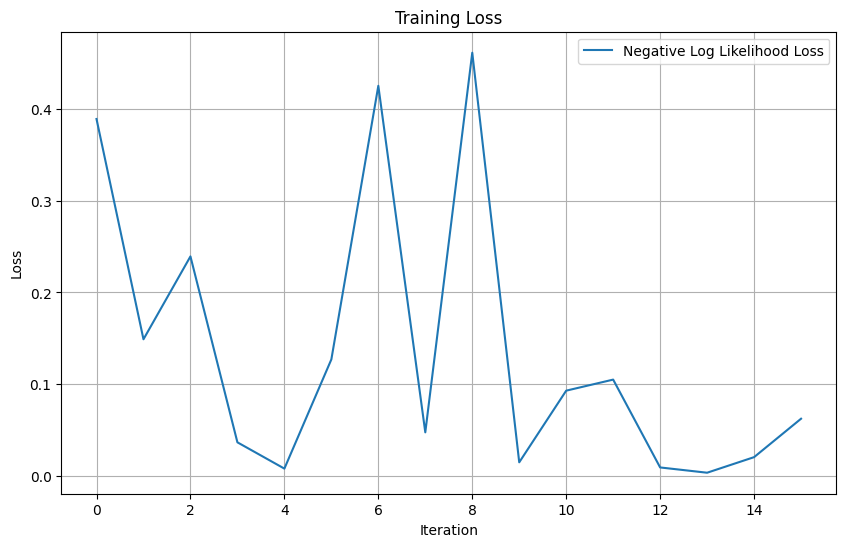

In [ ]:
import matplotlib.pyplot as plt

# Логування втрат
losses = []

for epoch in range(1):  # Тренуємо одну епоху
    for i, (recipe, tags) in enumerate(training_data):
        model_1.zero_grad()

        # Конвертуємо слова та теги в індекси
        encoded_recipe = converter.words_to_index(recipe)
        encoded_tags = converter.tags_to_index(tags)

        # Прогноз тегів
        tag_scores = model_1(encoded_recipe)

        # Розрахунок втрат
        loss = loss_function(tag_scores, encoded_tags)
        loss.backward()
        optimizer.step()


        # Виводимо прогрес кожні 500 ітерацій
        if i % 1000 == 0:
            print(f"Epoch {epoch + 1}, Step {i}, Loss: {loss.item()}")
            losses.append(loss.item())

        # Обмеження за кількістю ітерацій
        if i == 15000:
            break

# Графік втрат
plt.figure(figsize=(10, 6))
plt.plot(losses, label="Negative Log Likelihood Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()
plt.show()

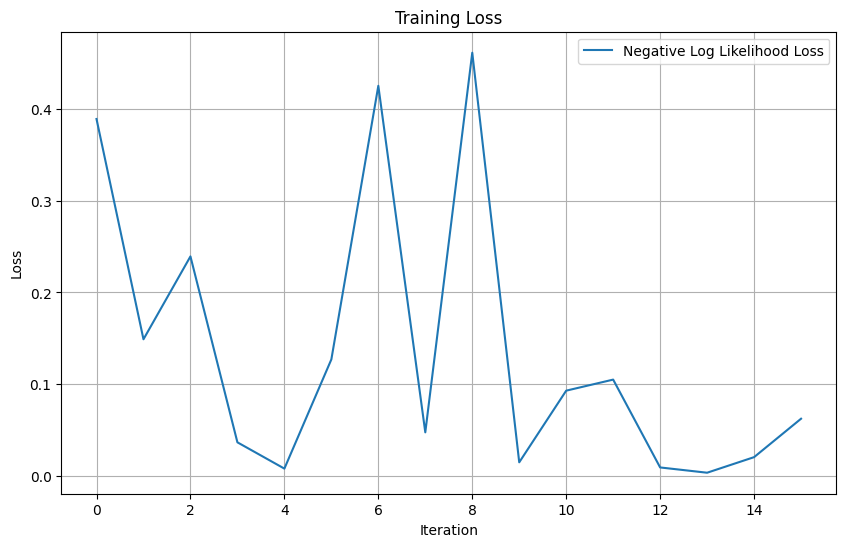

In [ ]:
# Графік втрат
plt.figure(figsize=(10, 6))
plt.plot(losses, label="Negative Log Likelihood Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()
plt.show()

Додаємо функцію для передбачення тегів

In [ ]:

def predict_tags(model, converter, recipe):
    # Конвертуємо слова у індекси
    encoded_recipe = converter.words_to_index(recipe)
    # Отримуємо передбачені теги (індекси)
    encoded_tags = model.predict_tags(encoded_recipe)
    # Перетворюємо індекси тегів у самі теги
    decoded_tags = converter.indices_to_tags(encoded_tags)
    return decoded_tags



Функція для виводу тегів поряд зі словами

In [ ]:

def show_markup_pycharms(recipe, tags):
    result = []
    for word, tag in zip(recipe, tags):
        result.append(f"{word} ({tag})")
    print(" ".join(result))

Створюємо цикл для порівняння пербачених та істиних тегів

In [ ]:

for i in range(10):
    # Випадковий рецепт з тестових даних
    recipe, tags = test_data[np.random.randint(0, len(test_data))]

    # Передбачення тегів
    tags_pred = predict_tags(model_1, converter, recipe)

    # Вивід істинних тегів
    print("Істинні теги:")
    show_markup_pycharms(recipe, tags)

    # Вивід передбачених тегів
    print("Передбачені теги:")
    show_markup_pycharms(recipe, tags_pred)

    print("-" * 50)  # Роздільник між рецептами

Істинні теги:
2 (B-QTY) scallions (B-NAME) , (OTHER) cleaned; (B-COMMENT) green (I-COMMENT) and (I-COMMENT) white (I-COMMENT) parts (I-COMMENT) cut (I-COMMENT) into (I-COMMENT) 2-inch (I-COMMENT) lengths (I-COMMENT)
Передбачені теги:
2 (B-QTY) scallions (B-NAME) , (OTHER) cleaned; (B-COMMENT) green (I-COMMENT) and (I-COMMENT) white (I-COMMENT) parts (I-COMMENT) cut (I-COMMENT) into (I-COMMENT) 2-inch (I-COMMENT) lengths (I-COMMENT)
--------------------------------------------------
Істинні теги:
3/4 (B-QTY) cup (B-UNIT) double (B-COMMENT) or (I-COMMENT) heavy (I-COMMENT) cream (B-NAME)
Передбачені теги:
3/4 (B-QTY) cup (B-UNIT) double (B-NAME) or (I-COMMENT) heavy (I-COMMENT) cream (I-COMMENT)
--------------------------------------------------
Істинні теги:
Salt (B-NAME) and (I-NAME) freshly (B-COMMENT) ground (I-COMMENT) pepper (B-NAME) to (B-COMMENT) taste (I-COMMENT)
Передбачені теги:
Salt (B-NAME) and (I-NAME) freshly (B-COMMENT) ground (I-COMMENT) pepper (B-NAME) to (B-COMMENT) ta

Зберігаємо параметри моделі

In [ ]:

torch.save(model_1.state_dict(), 'model_1.pt')


LSTMTagger(
  (word_embeddings): Embedding(5194, 32)
  (lstm): LSTM(32, 32)
  (hidden2tag): Linear(in_features=32, out_features=10, bias=True)
)

In [ ]:
model_1 = LSTMTagger(EMBEDDING_DIM, HIDDEN_DIM, VOCAB_SIZE, TAGSET_SIZE)
model_1.load_state_dict(torch.load('model_1.pt'))
model_1.eval()


LSTMTagger(
  (word_embeddings): Embedding(5194, 32)
  (lstm): LSTM(32, 32)
  (hidden2tag): Linear(in_features=32, out_features=10, bias=True)
)

Додаємо статисничний аналіз передбачень

In [ ]:
# Статистика по рецептах
def plot_recipe_statistics(correct_recipes, total_recipes=None):
    plt.rcdefaults()
    fig, ax = plt.subplots()
    descr, performance = zip(*correct_recipes.most_common())
    y_pos = np.arange(len(descr))

    if total_recipes is not None:
        performance = 100 * (np.array(performance) / float(total_recipes))
        ax.set_title('% Розмічених рецептів')
        ax.set_xlabel('% рецептів')
    else:
        ax.set_title('Кількість розмічених рецептів')
        ax.set_xlabel('Кількість рецептів')

    ax.barh(y_pos, performance, align='center')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(descr)
    ax.invert_yaxis()
    plt.show()

In [ ]:

# Матриця помилок
def plot_confusion_matrix(y_true, y_pred, classes, normalize=False, title=None, cmap=plt.cm.Blues):
    cm = confusion_matrix(y_true, y_pred, labels=classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=cmap)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=classes,
        yticklabels=classes,
        title=title,
        ylabel='Істинний тег',
        xlabel='Передбачений тег'
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    fig.tight_layout()
    return ax

In [ ]:

# Статистика рецептів
def recipe_statistics(model, converter, data, limit=None):
    correct_recipes = Counter()
    total_recipes = len(data)

    for recipe, tags in data:
        tags_pred = predict_tags(model, converter, recipe)
        tags_pred = np.array(tags_pred)
        tags = np.array(tags)

        noneq_num = np.sum(tags_pred != tags)
        if limit and noneq_num > limit:
            title = f'Рецепти з >{limit} помилками'
        elif noneq_num == 0:
            title = 'Рецепти без помилок'
        else:
            title = f'Рецепти з {noneq_num} помилками'

        correct_recipes[title] += 1

    return correct_recipes, total_recipes

In [ ]:
# Статистика тегів

def tag_statistics(model, converter, data):
    def tag_counter(predicted, ground):
        correct_tags = Counter()
        ground_tags = Counter(ground)
        for tag_p, tag_g in zip(predicted, ground):
            if tag_p == tag_g:
                correct_tags[tag_g] += 1
        return correct_tags, ground_tags

    total_correct, total_tags = Counter(), Counter()
    for recipe, tags in data:
        tags_pred = predict_tags(model, converter, recipe)
        tags_correct, tags_num = tag_counter(tags_pred, tags)
        total_correct.update(tags_correct)
        total_tags.update(tags_num)

    return total_correct, total_tags

In [ ]:

total_correct, total_tags = tag_statistics(model_1, converter, test_data)
print('Статистика вірно передбачених тегів:\n')
for tag in total_tags.keys():
    print(f'Для {tag}:')
    print(' Вірно:\t', total_correct[tag])
    print(' Всього:\t', total_tags[tag])
    print('% Вірно:\t', 100 * (total_correct[tag] / float(total_tags[tag])))
    print()

print('----------')
print('Загалом:')
print(' Вірно:\t', sum(total_correct.values()))
print(' Всього:\t', sum(total_tags.values()))
print('% Вірно:\t', 100 * (sum(total_correct.values()) / sum(total_tags.values())))

Статистика вірно передбачених тегів:

Для B-QTY:
 Вірно:	 8295
 Всього:	 8420
% Вірно:	 98.51543942992875

Для B-COMMENT:
 Вірно:	 5919
 Всього:	 7823
% Вірно:	 75.661510929311

Для B-RANGE_END:
 Вірно:	 146
 Всього:	 156
% Вірно:	 93.58974358974359

Для B-UNIT:
 Вірно:	 6940
 Всього:	 7074
% Вірно:	 98.10573932711337

Для B-NAME:
 Вірно:	 8885
 Всього:	 10278
% Вірно:	 86.44677952909127

Для I-NAME:
 Вірно:	 4543
 Всього:	 5528
% Вірно:	 82.18162083936325

Для I-COMMENT:
 Вірно:	 13973
 Всього:	 14984
% Вірно:	 93.25280298985584

Для OTHER:
 Вірно:	 1846
 Всього:	 4101
% Вірно:	 45.01341136308217

----------
Загалом:
 Вірно:	 50547
 Всього:	 58364
% Вірно:	 86.60646974162155


% Точність:	 86.60646974162155


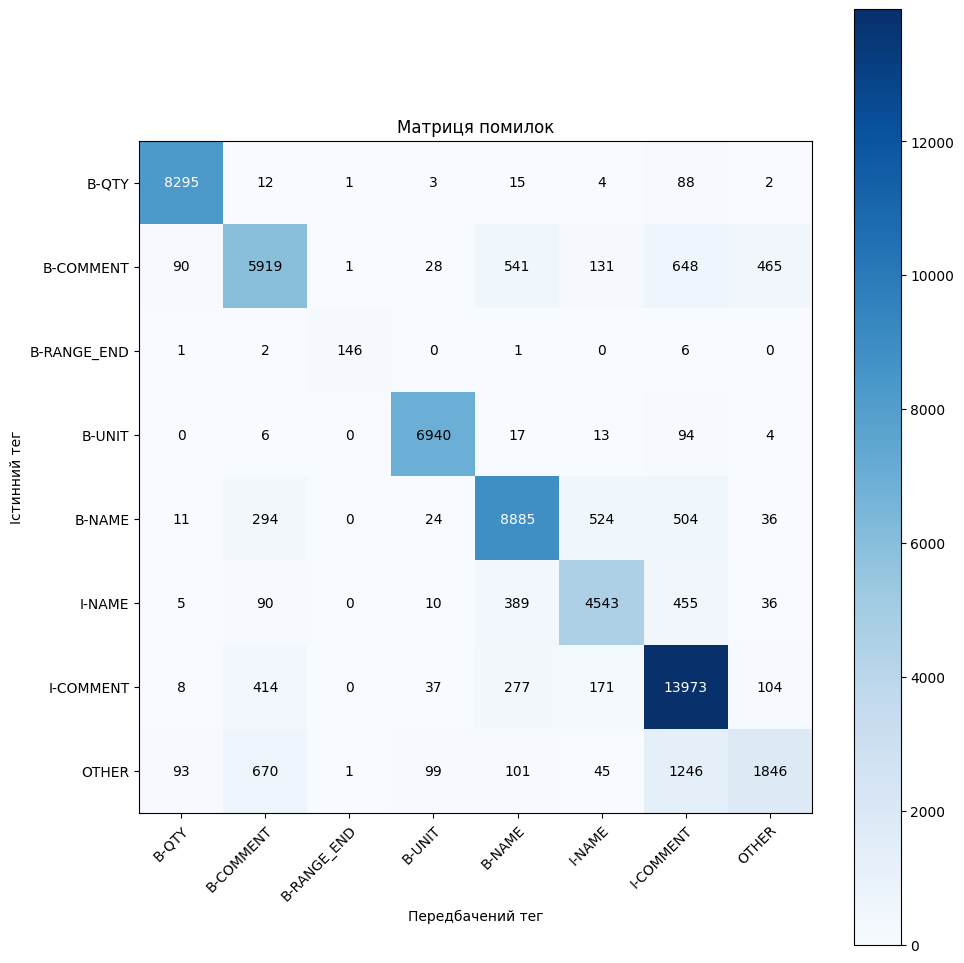

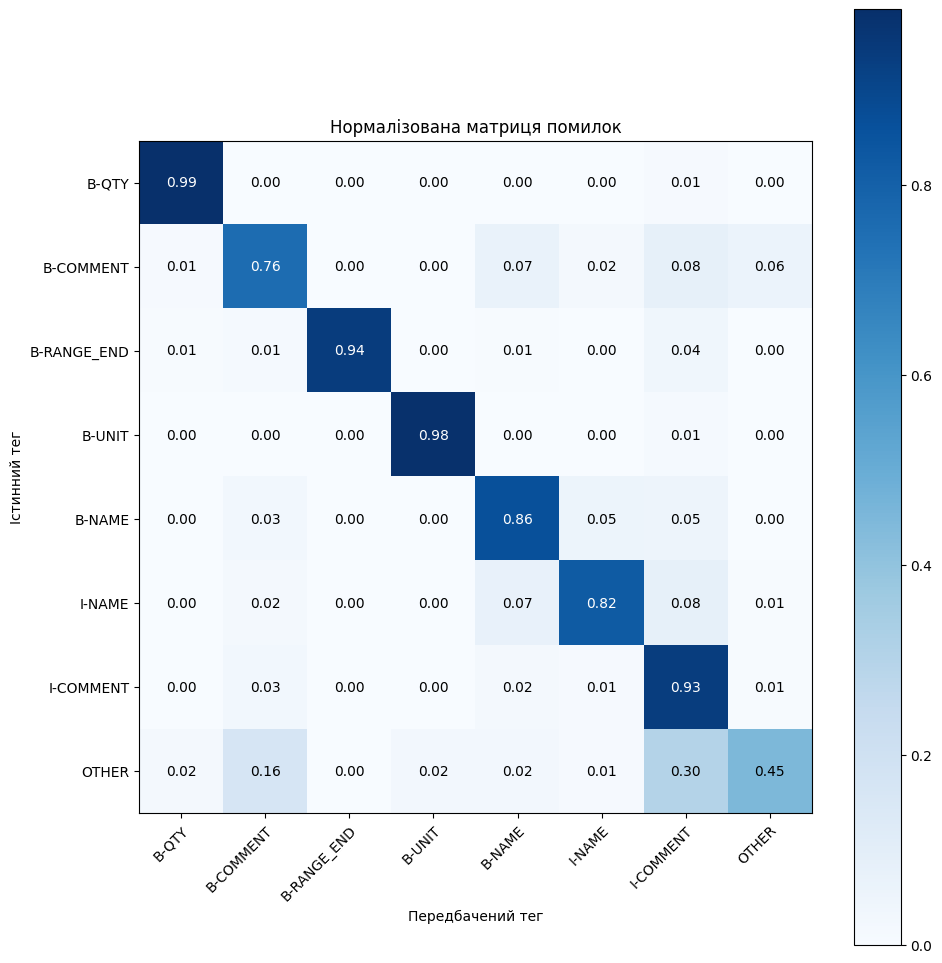

In [ ]:
# -------------------------------
# Матриця помилок
# -------------------------------
from sklearn.metrics import accuracy_score
y_pred = []
y_true = []
for recipe, tags in test_data:
    y_pred += predict_tags(model_1, converter, recipe)
    y_true += tags

print('% Точність:\t', accuracy_score(y_true, y_pred) * 100)

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), title='Матриця помилок')
plt.show()

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), normalize=True, title='Нормалізована матриця помилок')
plt.show()


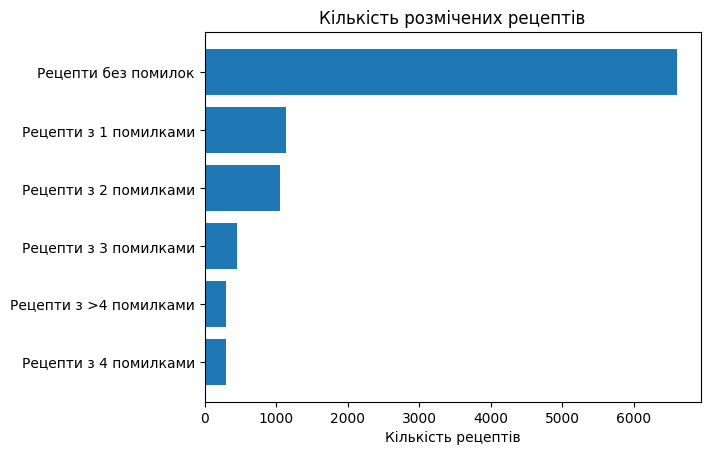

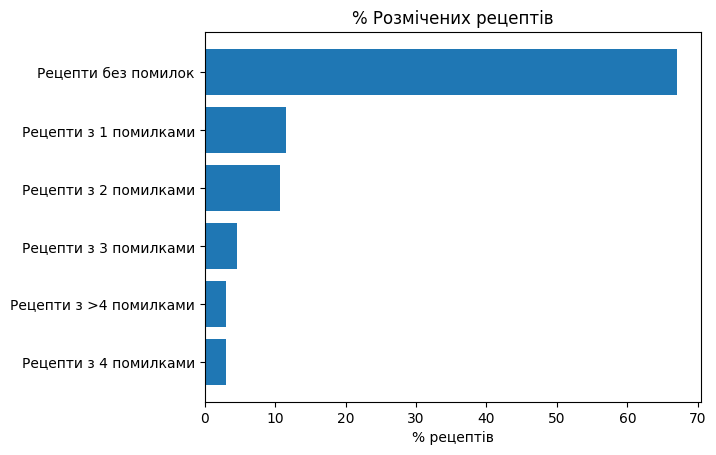

In [ ]:
# -------------------------------
# Статистика рецептів
# -------------------------------
correct_recipes, total_recipes = recipe_statistics(model_1, converter, test_data, limit=4)
plot_recipe_statistics(correct_recipes)
plot_recipe_statistics(correct_recipes, total_recipes)

Загальна точність моделі становить 86.61%. Найкраще мережв передбачає структуровані й формалізовані сутності: B-QTY (98%), B-UNIT (98%) та B-RANGE_END (93%). Це очікувано, оскільки кількості та одиниці виміру мають чіткі лексичні шаблони (числа, скорочення, стандартизовані назви).

Досить високі результати спостерігаються також для I-COMMENT  та B-NAME, тобто модель іноді помиляється у визначенні меж складених назв інгредієнтів. Наприклад, у випадку “large yellow onion” слово onion було віднесене до I-NAME замість B-NAME, що свідчить про труднощі з визначенням початку нової сутності.

Найгірше модель працює з тегом OTHER. Ймовірно, це пов’язано з його широкою та нечітко визначеною природою: до цієї категорії можуть потрапляти різнорідні токени.
Тобто, основні помилки виникають у розмежуванні B-NAME / I-NAME та B-COMMENT / B-NAME. Наприклад, у фразі “double or heavy cream” слово double було класифіковане як B-NAME замість B-COMMENT, що демонструє труднощі у відокремленні описових характеристик від власне назви інгредієнта. Аналогічно, у прикладі з “ancho chilies” слово ancho було віднесене до I-COMMENT замість B-NAME.



Спробуємо покращити модель і збільшимо розмір ембендінгів

In [ ]:
EMBEDDING_DIM = 64
# DROPOUT = 0.1
HIDDEN_DIM = 32
VOCAB_SIZE = len(converter.word_to_idx)
TAGSET_SIZE = len(converter.tag_to_idx)
# Ініціалізація моделі, функції втрат та оптимізатора
model_2 = LSTMTagger(EMBEDDING_DIM, HIDDEN_DIM, VOCAB_SIZE, TAGSET_SIZE)
loss_function = nn.NLLLoss()
optimizer = optim.SGD(model_2.parameters(), lr=0.1)

In [ ]:


# Логування втрат
losses_2 = []

for epoch in range(1):  # Тренуємо одну епоху
    for i, (recipe, tags) in enumerate(training_data):
        model_2.zero_grad()

        # Конвертуємо слова та теги в індекси
        encoded_recipe = converter.words_to_index(recipe)
        encoded_tags = converter.tags_to_index(tags)

        # Прогноз тегів
        tag_scores = model_2(encoded_recipe)

        # Розрахунок втрат
        loss = loss_function(tag_scores, encoded_tags)
        loss.backward()
        optimizer.step()


        # Виводимо прогрес кожні 500 ітерацій
        if i % 1000 == 0:
            print(f"Epoch {epoch + 1}, Step {i}, Loss: {loss.item()}")
            losses_2.append(loss.item())

        # Обмеження за кількістю ітерацій
        if i == 15000:
            break



Epoch 1, Step 0, Loss: 2.3471550941467285
Epoch 1, Step 1000, Loss: 0.5126177072525024
Epoch 1, Step 2000, Loss: 1.43551504611969
Epoch 1, Step 3000, Loss: 0.15719883143901825
Epoch 1, Step 4000, Loss: 0.025348370894789696
Epoch 1, Step 5000, Loss: 0.22299198806285858
Epoch 1, Step 6000, Loss: 0.279594749212265
Epoch 1, Step 7000, Loss: 0.25784972310066223
Epoch 1, Step 8000, Loss: 0.3097015917301178
Epoch 1, Step 9000, Loss: 0.021425437182188034
Epoch 1, Step 10000, Loss: 0.1101657897233963
Epoch 1, Step 11000, Loss: 0.08000877499580383
Epoch 1, Step 12000, Loss: 0.07487914711236954
Epoch 1, Step 13000, Loss: 0.009205673821270466
Epoch 1, Step 14000, Loss: 0.051704712212085724
Epoch 1, Step 15000, Loss: 0.07011140882968903


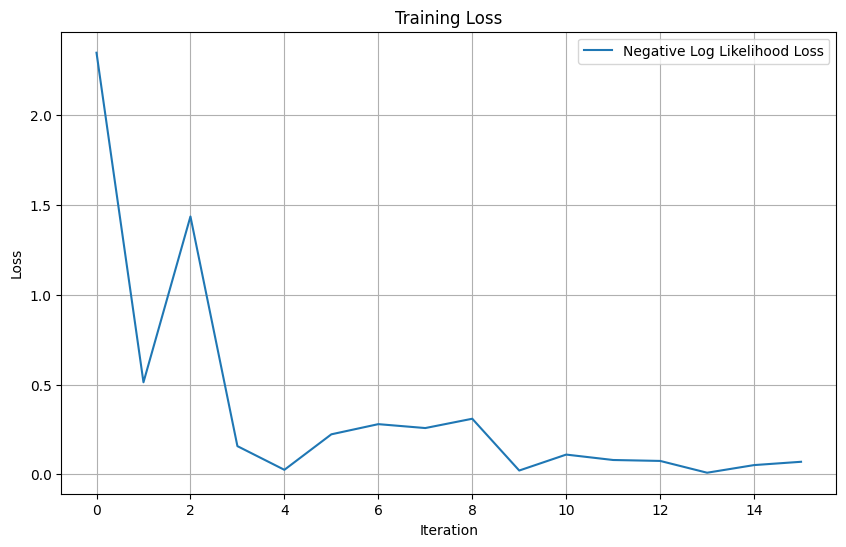

In [ ]:
# Графік втрат
plt.figure(figsize=(10, 6))
plt.plot(losses_2, label="Negative Log Likelihood Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()
plt.show()

Можна побачити, що помилка впродовж епох падає більш стабільно

In [ ]:
# -------------------------------
# Вивід статистики тегів
# -------------------------------
total_correct, total_tags = tag_statistics(model_2, converter, test_data)
print('Статистика вірно передбачених тегів:\n')
for tag in total_tags.keys():
    print(f'Для {tag}:')
    print(' Вірно:\t', total_correct[tag])
    print(' Всього:\t', total_tags[tag])
    print('% Вірно:\t', 100 * (total_correct[tag] / float(total_tags[tag])))
    print()

print('----------')
print('Загалом:')
print(' Вірно:\t', sum(total_correct.values()))
print(' Всього:\t', sum(total_tags.values()))
print('% Вірно:\t', 100 * (sum(total_correct.values()) / sum(total_tags.values())))




Статистика вірно передбачених тегів:

Для B-QTY:
 Вірно:	 8294
 Всього:	 8420
% Вірно:	 98.50356294536817

Для B-COMMENT:
 Вірно:	 5566
 Всього:	 7823
% Вірно:	 71.1491755081171

Для B-RANGE_END:
 Вірно:	 70
 Всього:	 156
% Вірно:	 44.871794871794876

Для B-UNIT:
 Вірно:	 6910
 Всього:	 7074
% Вірно:	 97.68165111676562

Для B-NAME:
 Вірно:	 8739
 Всього:	 10278
% Вірно:	 85.02626970227671

Для I-NAME:
 Вірно:	 4408
 Всього:	 5528
% Вірно:	 79.73950795947901

Для I-COMMENT:
 Вірно:	 13422
 Всього:	 14984
% Вірно:	 89.57554725040042

Для OTHER:
 Вірно:	 1968
 Всього:	 4101
% Вірно:	 47.988295537673736

----------
Загалом:
 Вірно:	 49377
 Всього:	 58364
% Вірно:	 84.60180933452128


% Точність:	 84.60180933452128


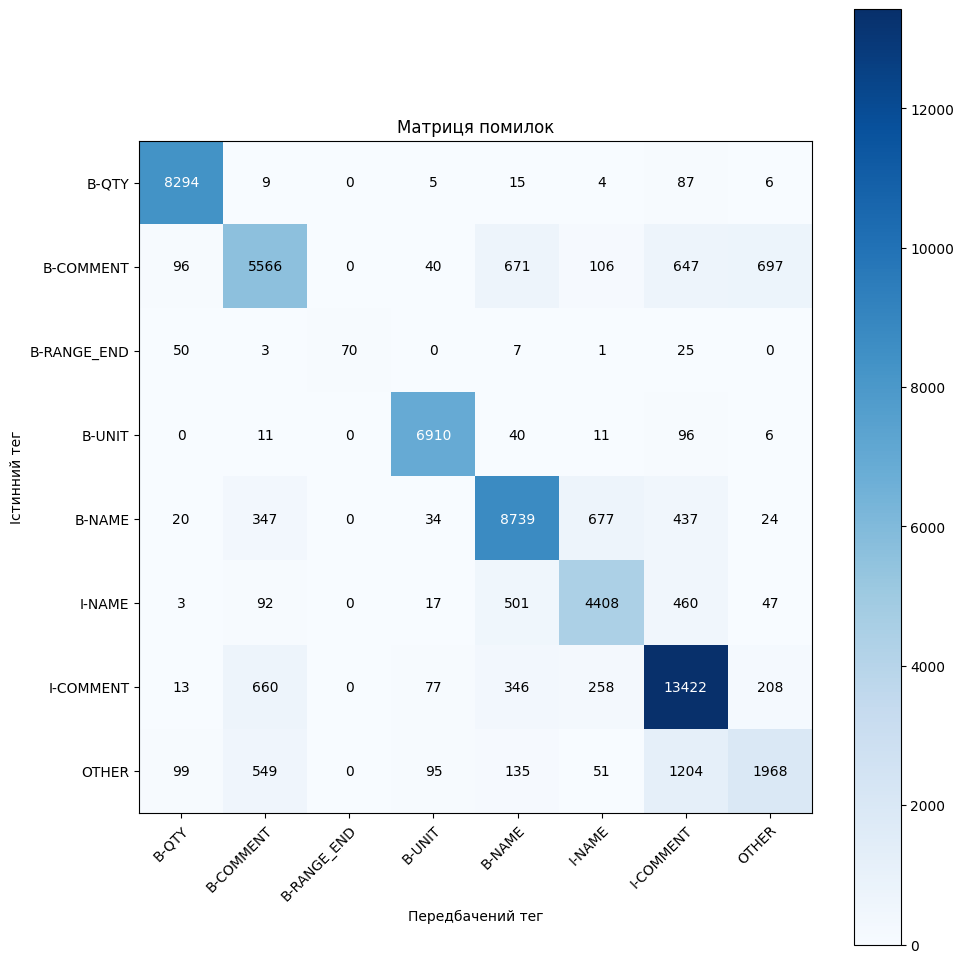

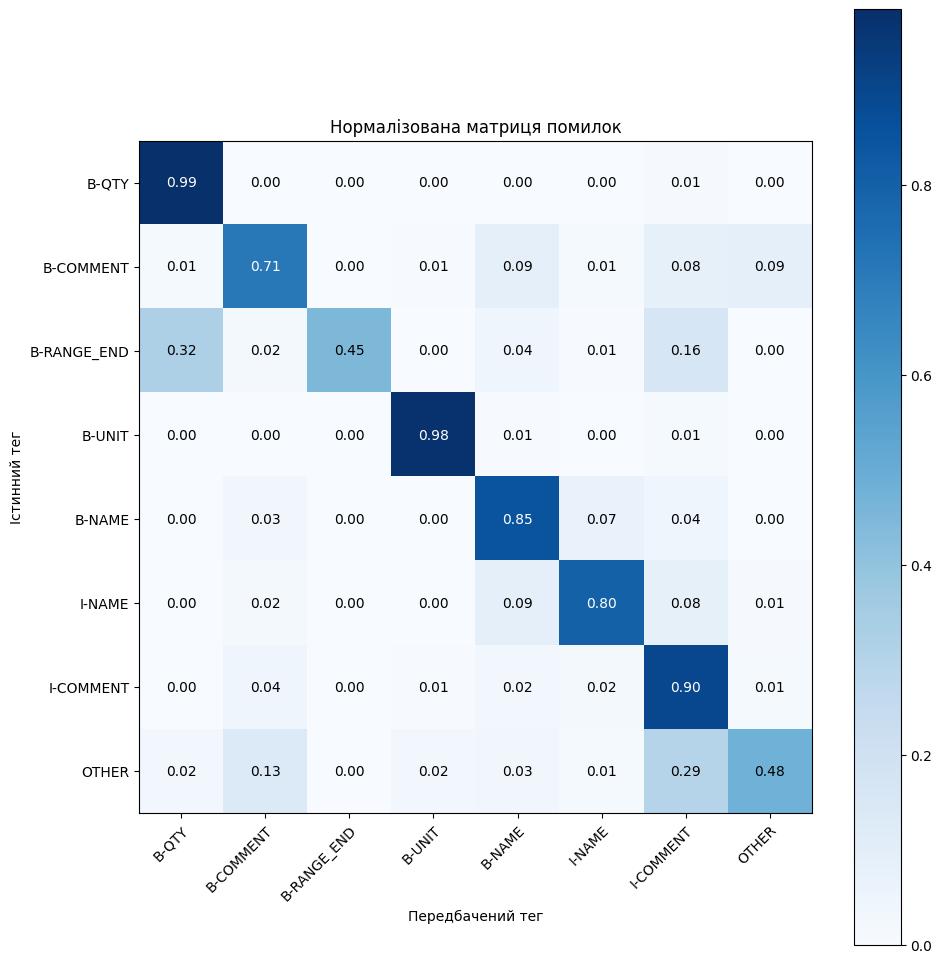

In [ ]:
# -------------------------------
# Матриця помилок
# -------------------------------

y_pred = []
y_true = []
for recipe, tags in test_data:
    y_pred += predict_tags(model_2, converter, recipe)
    y_true += tags

print('% Точність:\t', accuracy_score(y_true, y_pred) * 100)

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), title='Матриця помилок')
plt.show()

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), normalize=True, title='Нормалізована матриця помилок')
plt.show()

Проте загальна точність поделі впала з 86% до 84%

Додамо шари до LSTM та дропаут. Для цього створимо новий клас

In [ ]:


class LSTMTagger_dropout(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, tagset_size, dropout_p=0.2):
        super(LSTMTagger_dropout, self).__init__()
        self.hidden_dim = hidden_dim

        # Ембеддинги
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim)


        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            dropout=dropout_p
        )

        # Dropout перед фінальним шаром
        self.dropout = nn.Dropout(p=dropout_p)

        # Лінійний шар для прогнозу тегів
        self.hidden2tag = nn.Linear(hidden_dim, tagset_size)

    def forward(self, words):
        embeds = self.word_embeddings(words)               # (seq_len, embedding_dim)
        lstm_out, _ = self.lstm(embeds.view(len(words), 1, -1))
        lstm_out = self.dropout(lstm_out)                 # застосовуємо Dropout
        tag_space = self.hidden2tag(lstm_out.view(len(words), -1))
        tag_scores = F.log_softmax(tag_space, dim=1)
        return tag_scores

    def predict_tags(self, words):
        with torch.no_grad():
            tag_scores = self.forward(words)
            tags_pred = torch.argmax(tag_scores, dim=1).numpy()
        return tags_pred

In [ ]:
EMBEDDING_DIM = 64
DROPOUT = 0.1
HIDDEN_DIM = 64
VOCAB_SIZE = len(converter.word_to_idx)
TAGSET_SIZE = len(converter.tag_to_idx)
# Ініціалізація моделі, функції втрат та оптимізатора
model_3 = LSTMTagger_dropout(EMBEDDING_DIM, HIDDEN_DIM, VOCAB_SIZE, TAGSET_SIZE, DROPOUT)
loss_function = nn.NLLLoss()
optimizer = optim.SGD(model_3.parameters(), lr=0.1)

In [ ]:


torch.manual_seed(42)
# Логування втрат
losses_3 = []

for epoch in range(1):  # Тренуємо одну епоху
    for i, (recipe, tags) in enumerate(training_data):
        model_3.zero_grad()

        # Конвертуємо слова та теги в індекси
        encoded_recipe = converter.words_to_index(recipe)
        encoded_tags = converter.tags_to_index(tags)

        # Прогноз тегів
        tag_scores = model_3(encoded_recipe)

        # Розрахунок втрат
        loss = loss_function(tag_scores, encoded_tags)
        loss.backward()
        optimizer.step()


        # Виводимо прогрес кожні 500 ітерацій
        if i % 1000 == 0:
            print(f"Epoch {epoch + 1}, Step {i}, Loss: {loss.item()}")
            losses_3.append(loss.item())

        # Обмеження за кількістю ітерацій
        if i == 15000:
            break



Epoch 1, Step 0, Loss: 2.365687131881714
Epoch 1, Step 1000, Loss: 0.5990478992462158
Epoch 1, Step 2000, Loss: 1.0955287218093872
Epoch 1, Step 3000, Loss: 0.12701328098773956
Epoch 1, Step 4000, Loss: 0.011097035370767117
Epoch 1, Step 5000, Loss: 0.7035897374153137
Epoch 1, Step 6000, Loss: 0.21997003257274628
Epoch 1, Step 7000, Loss: 0.3192030191421509
Epoch 1, Step 8000, Loss: 0.3897814154624939
Epoch 1, Step 9000, Loss: 0.055023930966854095
Epoch 1, Step 10000, Loss: 0.0597183033823967
Epoch 1, Step 11000, Loss: 0.5920383930206299
Epoch 1, Step 12000, Loss: 0.020037351176142693
Epoch 1, Step 13000, Loss: 0.006058004219084978
Epoch 1, Step 14000, Loss: 0.04659689590334892
Epoch 1, Step 15000, Loss: 0.10731115192174911


In [ ]:
# -------------------------------
# Вивід статистики тегів
# -------------------------------
total_correct, total_tags = tag_statistics(model_3, converter, test_data)
print('Статистика вірно передбачених тегів:\n')
for tag in total_tags.keys():
    print(f'Для {tag}:')
    print(' Вірно:\t', total_correct[tag])
    print(' Всього:\t', total_tags[tag])
    print('% Вірно:\t', 100 * (total_correct[tag] / float(total_tags[tag])))
    print()

print('----------')
print('Загалом:')
print(' Вірно:\t', sum(total_correct.values()))
print(' Всього:\t', sum(total_tags.values()))
print('% Вірно:\t', 100 * (sum(total_correct.values()) / sum(total_tags.values())))





Статистика вірно передбачених тегів:

Для B-QTY:
 Вірно:	 8296
 Всього:	 8420
% Вірно:	 98.52731591448931

Для B-COMMENT:
 Вірно:	 5377
 Всього:	 7823
% Вірно:	 68.73322254889429

Для B-RANGE_END:
 Вірно:	 125
 Всього:	 156
% Вірно:	 80.12820512820514

Для B-UNIT:
 Вірно:	 6868
 Всього:	 7074
% Вірно:	 97.08792762227877

Для B-NAME:
 Вірно:	 8989
 Всього:	 10278
% Вірно:	 87.45864954271258

Для I-NAME:
 Вірно:	 4449
 Всього:	 5528
% Вірно:	 80.48118668596237

Для I-COMMENT:
 Вірно:	 13626
 Всього:	 14984
% Вірно:	 90.93699946609716

Для OTHER:
 Вірно:	 1959
 Всього:	 4101
% Вірно:	 47.76883686905633

----------
Загалом:
 Вірно:	 49689
 Всього:	 58364
% Вірно:	 85.13638544308135
% Точність:	 84.60180933452128


% Точність:	 85.20663422657803


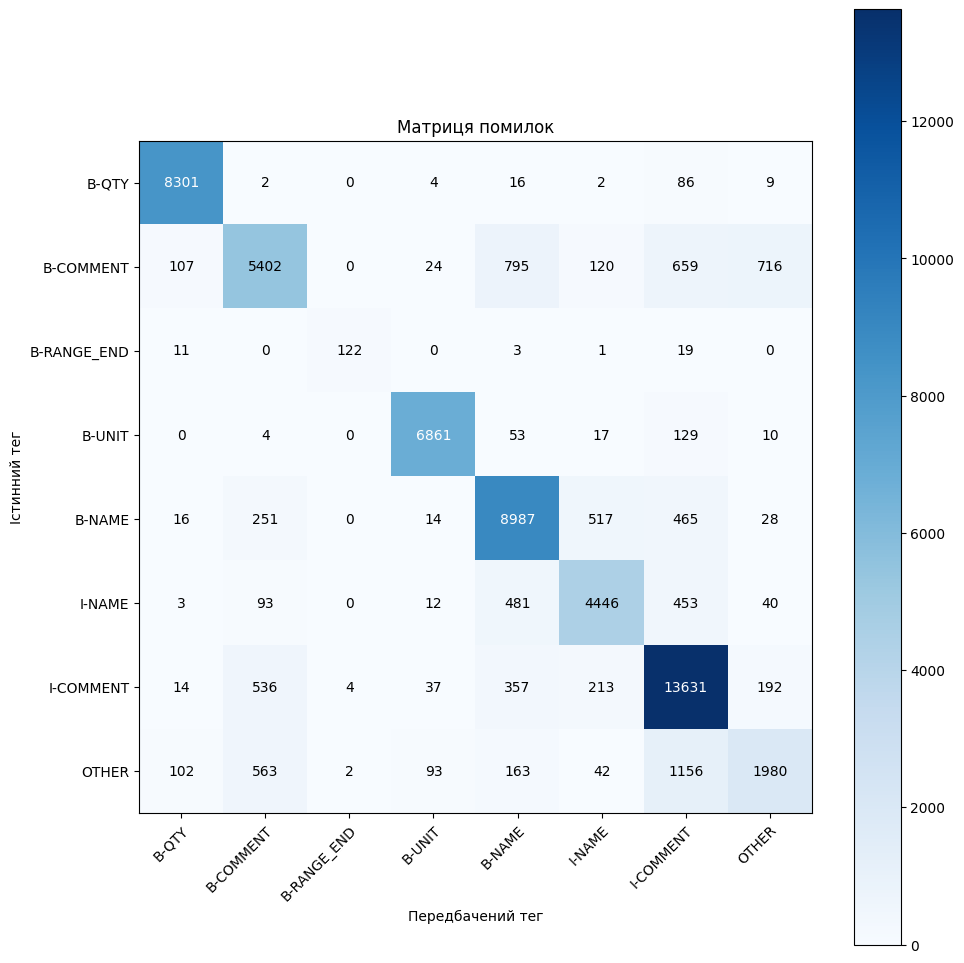

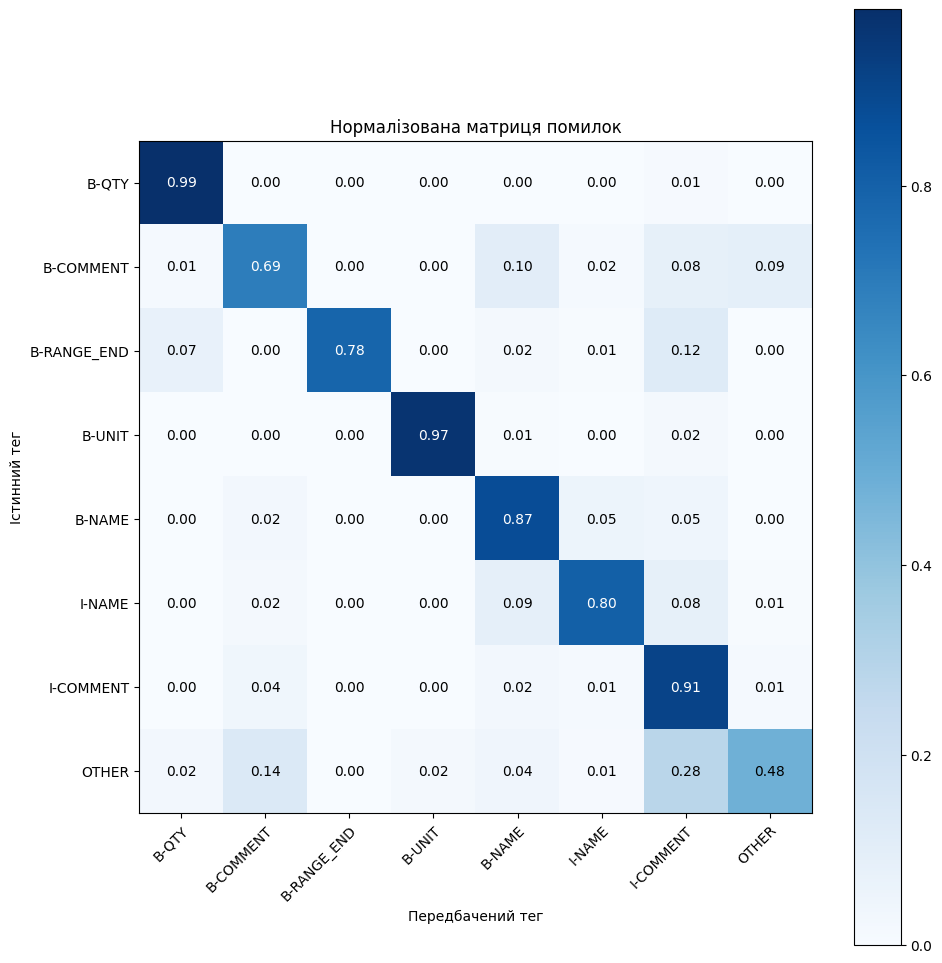

In [ ]:
# -------------------------------
# Матриця помилок
# -------------------------------

y_pred = []
y_true = []
for recipe, tags in test_data:
    y_pred += predict_tags(model_3, converter, recipe)
    y_true += tags

print('% Точність:\t', accuracy_score(y_true, y_pred) * 100)

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), title='Матриця помилок')
plt.show()

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), normalize=True, title='Нормалізована матриця помилок')
plt.show()

Додавання прихованого шару, збільшення кількості ембендингів та додавання дропату загалом не покращили загальну точність моделі. Тому найперший варіант конфігурації є найкращим із запропонованих

Наступний крок полягає у використанні Bidirectional LSTM замість
звичайної LSTM.

Для зручності створимо інший клас, не використовуючи успадкування

In [ ]:

class BidirectionalLSTMTagger(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, tagset_size):
        super(BidirectionalLSTMTagger, self).__init__()

        self.hidden_dim = hidden_dim

        # Embedding
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim)

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            bidirectional=True
        )

        # ВАЖЛИВО: hidden_dim * 2 через bidirectional
        self.hidden2tag = nn.Linear(hidden_dim * 2, tagset_size)

    def forward(self, words):
        embeds = self.word_embeddings(words)

        lstm_out, _ = self.lstm(embeds.view(len(words), 1, -1))

        # hidden_dim * 2 через двонаправленість
        tag_space = self.hidden2tag(lstm_out.view(len(words), -1))

        tag_scores = F.log_softmax(tag_space, dim=1)
        return tag_scores

    def predict_tags(self, words):
        with torch.no_grad():
            tag_scores = self.forward(words)
            tags_pred = torch.argmax(tag_scores, dim=1)
        return tags_pred.numpy()

In [ ]:


EMBEDDING_DIM = 32
HIDDEN_DIM = 32
VOCAB_SIZE = len(converter.word_to_idx)
TAGSET_SIZE = len(converter.tag_to_idx)
# Ініціалізація моделі, функції втрат та оптимізатора
model_4 = BidirectionalLSTMTagger(EMBEDDING_DIM, HIDDEN_DIM, VOCAB_SIZE, TAGSET_SIZE)
loss_function = nn.NLLLoss()
optimizer = optim.SGD(model_4.parameters(), lr=0.1)


In [ ]:
# Логування втрат
torch.manual_seed(42)
losses_4 = []

for epoch in range(1):  # Тренуємо одну епоху
    for i, (recipe, tags) in enumerate(training_data):
        model_4.zero_grad()

        # Конвертуємо слова та теги в індекси
        encoded_recipe = converter.words_to_index(recipe)  # слово -> індекс
        encoded_tags = converter.tags_to_index(tags)       # теги -> індекси

        # Прогноз тегів
        tag_scores = model_4(encoded_recipe)

        # Розрахунок втрат
        loss = loss_function(tag_scores, encoded_tags)
        loss.backward()
        optimizer.step()


        # Виводимо прогрес кожні 500 ітерацій
        if i % 1000 == 0:
            print(f"Epoch {epoch + 1}, Step {i}, Loss: {loss.item()}")
            losses_4.append(loss.item())

        # Обмеження за кількістю ітерацій
        if i == 15000:
            break


Epoch 1, Step 0, Loss: 0.5253140330314636
Epoch 1, Step 1000, Loss: 1.097686529159546
Epoch 1, Step 2000, Loss: 0.33856725692749023
Epoch 1, Step 3000, Loss: 0.04439043626189232
Epoch 1, Step 4000, Loss: 0.01026451401412487
Epoch 1, Step 5000, Loss: 0.24846912920475006
Epoch 1, Step 6000, Loss: 0.24979564547538757
Epoch 1, Step 7000, Loss: 0.2970055639743805
Epoch 1, Step 8000, Loss: 0.5553358793258667
Epoch 1, Step 9000, Loss: 0.006443388760089874
Epoch 1, Step 10000, Loss: 0.13222065567970276
Epoch 1, Step 11000, Loss: 0.013117887079715729
Epoch 1, Step 12000, Loss: 0.02504514902830124
Epoch 1, Step 13000, Loss: 0.004976413678377867
Epoch 1, Step 14000, Loss: 0.026269149035215378
Epoch 1, Step 15000, Loss: 0.062461968511343


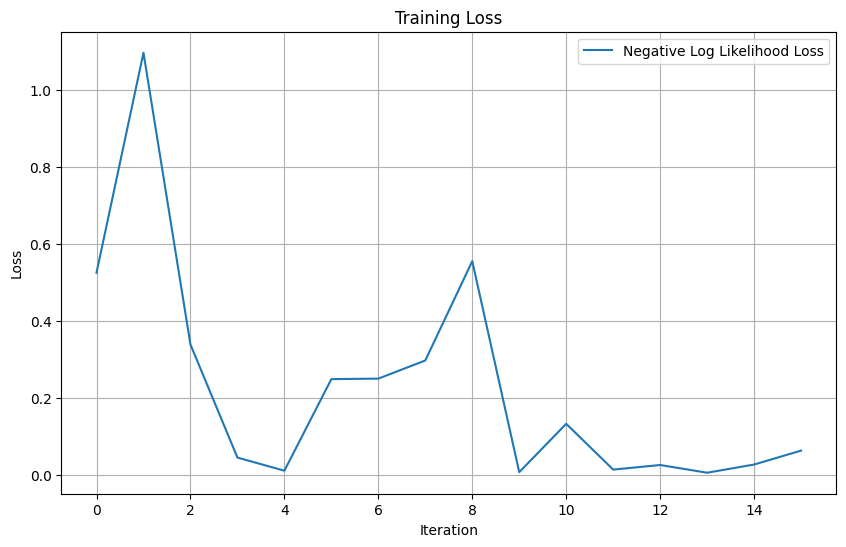

In [ ]:

# Графік втрат
plt.figure(figsize=(10, 6))
plt.plot(losses_4, label="Negative Log Likelihood Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# -------------------------------
# Вивід статистики тегів
# -------------------------------
total_correct, total_tags = tag_statistics(model_4, converter, test_data)
print('Статистика вірно передбачених тегів:\n')
for tag in total_tags.keys():
    print(f'Для {tag}:')
    print(' Вірно:\t', total_correct[tag])
    print(' Всього:\t', total_tags[tag])
    print('% Вірно:\t', 100 * (total_correct[tag] / float(total_tags[tag])))
    print()

print('----------')
print('Загалом:')
print(' Вірно:\t', sum(total_correct.values()))
print(' Всього:\t', sum(total_tags.values()))
print('% Вірно:\t', 100 * (sum(total_correct.values()) / sum(total_tags.values())))





Статистика вірно передбачених тегів:

Для B-QTY:
 Вірно:	 8288
 Всього:	 8420
% Вірно:	 98.43230403800474

Для B-COMMENT:
 Вірно:	 5781
 Всього:	 7823
% Вірно:	 73.89748178448166

Для B-RANGE_END:
 Вірно:	 143
 Всього:	 156
% Вірно:	 91.66666666666666

Для B-UNIT:
 Вірно:	 6932
 Всього:	 7074
% Вірно:	 97.99264913768731

Для B-NAME:
 Вірно:	 8746
 Всього:	 10278
% Вірно:	 85.09437633780891

Для I-NAME:
 Вірно:	 4594
 Всього:	 5528
% Вірно:	 83.1041968162084

Для I-COMMENT:
 Вірно:	 13661
 Всього:	 14984
% Вірно:	 91.17058195408435

Для OTHER:
 Вірно:	 2053
 Всього:	 4101
% Вірно:	 50.060960741282614

----------
Загалом:
 Вірно:	 50198
 Всього:	 58364
% Вірно:	 86.00849838941814


% Точність:	 86.00849838941814


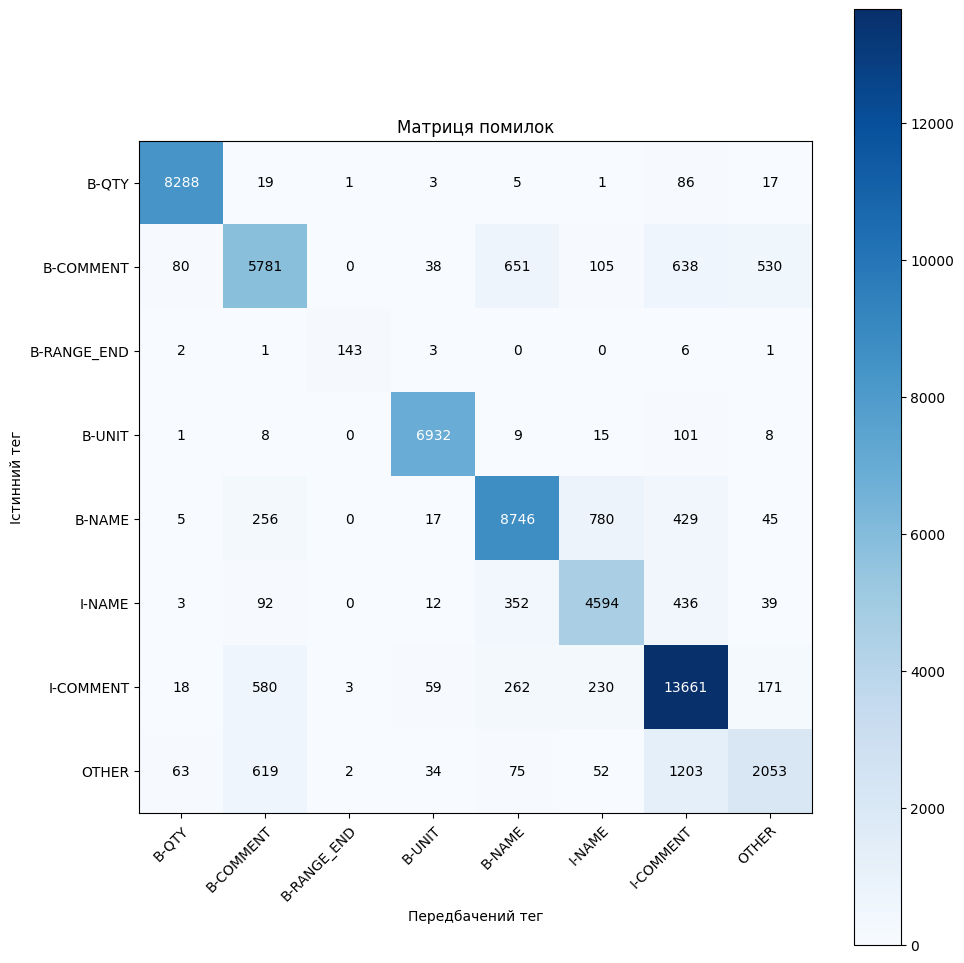

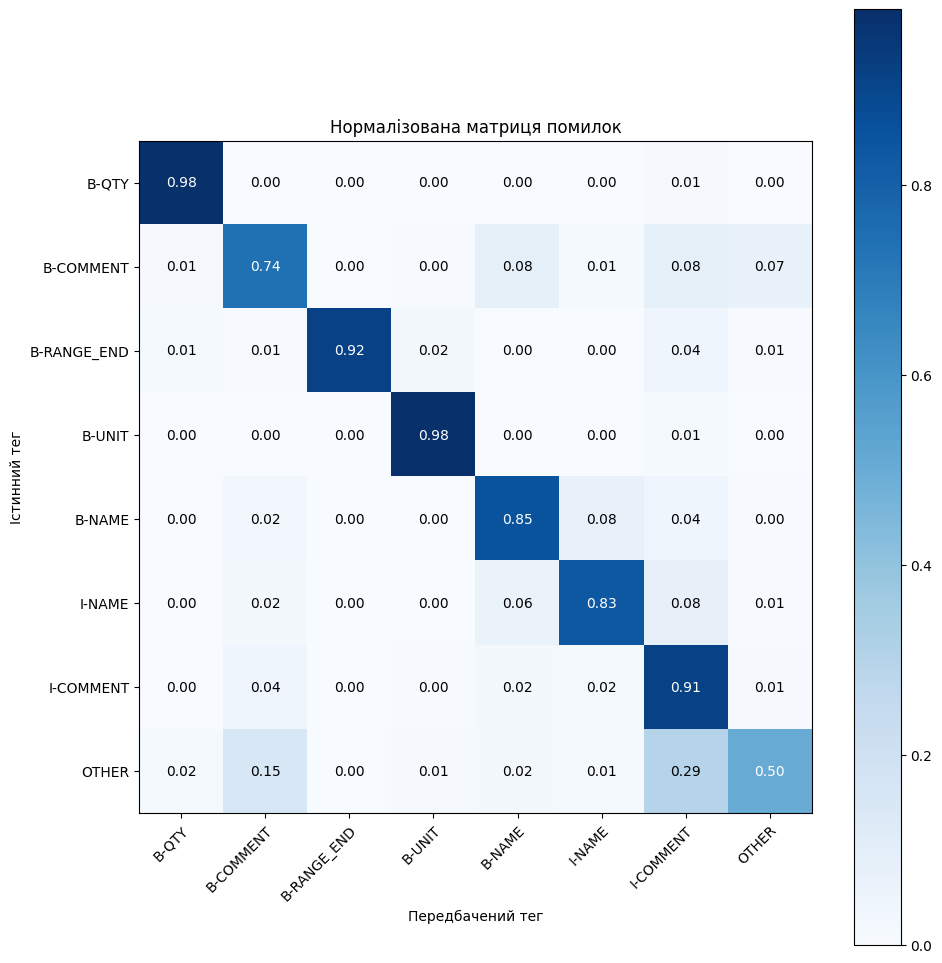

In [ ]:
# -------------------------------
# Матриця помилок
# -------------------------------

y_pred = []
y_true = []
for recipe, tags in test_data:
    y_pred += predict_tags(model_4, converter, recipe)
    y_true += tags

print('% Точність:\t', accuracy_score(y_true, y_pred) * 100)

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), title='Матриця помилок')
plt.show()

plot_confusion_matrix(y_true, y_pred, classes=list(total_tags.keys()), normalize=True, title='Нормалізована матриця помилок')
plt.show()

Порівняно зі звичайною LSTM, використання Bidirectional LSTM не призвело до покращення загальної точності: вона знизилась з 86.61% до 86.01%. Отже, двонапрямна архітектура не дала суттєвої переваги для поданої задачі.

Найкращі результати, як і раніше, спостерігаються для формалізованих тегів.  Для тегів назв інгредієнтів результати змінилися неоднорідно: I-NAME дещо покращився (83.10% проти 82.18%), що можна пояснити кращим урахуванням правого контексту. Водночас B-NAME знизився (85.09% проти 86.45%).
Найбільш помітні зміни стосуються OTHER: точність зросла з 45.01% до 50.06%. Це означає, що двонапрямний контекст допомагає краще відрізняти службові слова та розділові знаки від сусідніх категорій. Водночас якість для B-COMMENT та I-COMMENT знизилась, що може вказувати на часткове змішування описових фрагментів з іншими типами сутностей.


Отже, Bidirectional LSTM частково покращила розпізнавання внутрішніх елементів складених сутностей  та категорії OTHER, однак загальна якість моделі залишилась практично на тому ж рівні. Для помітного приросту якості, ймовірно, необхідна більш складна архітектура  або використання ембедингів більшої розмірності.